In [1]:
import numpy as np
import matplotlib.pyplot as plt
from utils import PACBayesCurve
from data.ibl.utils import load_behavior_data, block_average
from scipy.stats import pearsonr, spearmanr

In [2]:
# figure formatting (as in the original notebooks)
import seaborn as sns
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['figure.dpi'] = 100

# basic prediction of the theory: scaling law, effective dimensionality

## Section 1: PAC-Bayes Learning Curve
Aggregate learning-curve analysis on the full CSV cohort (140 mice, 7 labs): the per-lab
average fit, the spread of individual $\alpha$ / $\phi$, and how learning speed relates to them.

In [3]:
all_data, uuid, col_names = load_behavior_data()
labs = list(all_data.keys())
all_sub = [all_data[lab][s] for lab in labs for s in all_data[lab]]
print(f'{len(all_sub)} subjects across {len(labs)} labs')

140 subjects across 7 labs


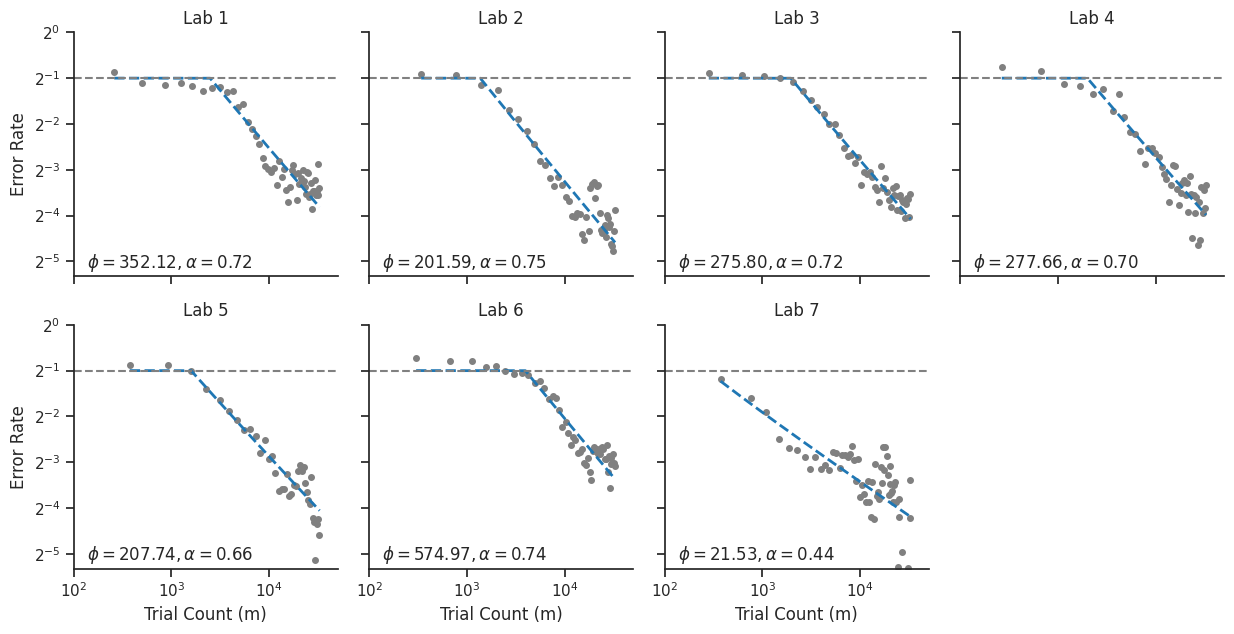

In [1]:
# per-lab average learning curves (power-law / PAC-Bayes fit)
fig, axs = plt.subplots(2, 4, figsize=(12.5, 6.5), sharex=True, sharey=True)
axs = axs.flatten()

for i, lab in enumerate(labs):
    ax = axs[i]
    sub_data_list = [all_data[lab][sub] for sub in all_data[lab].keys()]
    n_trials, p_correct = block_average(sub_data_list)

    cutoff = 32768  # 2**15
    m_trials = np.cumsum(n_trials)
    m_trials = m_trials[m_trials <= cutoff]
    p_correct = p_correct[:len(m_trials)]

    # error rate vs trial count in log-log space
    ax.plot(m_trials, 1 - p_correct, 'o', markersize=4, color='grey')
    ax.set_xscale('log'); ax.set_yscale('log', base=2)   # base 10 has only one tick in this y range
    ax.set(xlim=[1e2, 5e4], ylim=[0.025, 1], yticks=2.0 ** np.arange(-5, 1))
    ax.minorticks_off()

    # fit power-law and PAC-Bayes; show the PAC-Bayes fit    
    pb = PACBayesCurve(cap=0.5).fit(m_trials, 1 - p_correct)     # g(m) = (2/3) phi/m + (2 phi/m) ** alpha
    m_range = np.arange(np.min(m_trials), cutoff + 1)
    ax.plot(m_range, pb.predict(m_range), '--', color='tab:blue', linewidth=2)
    ax.text(0.05, 0.1, r'$\phi=%.2f, \alpha=%.2f$' % (pb.params['phi'], pb.params['alpha']),
            transform=ax.transAxes, verticalalignment='top')

    ax.set_title(lab); ax.set_xlabel('Trial Count (m)'); ax.set_ylabel('Error Rate')
    ax.axhline(y=0.5, color='gray', linestyle='--'); ax.label_outer()

axs.flat[-1].set_axis_off()
plt.tight_layout()
plt.savefig('./per_lab_curves.pdf', bbox_inches='tight', dpi=300)
plt.show()

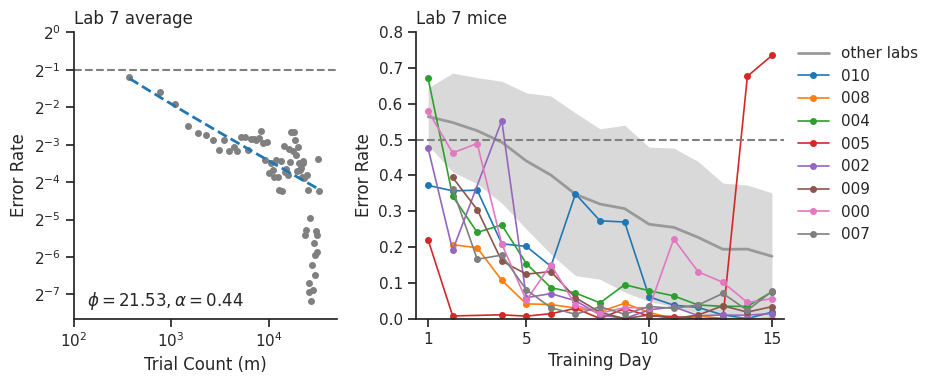

In [1]:
# Lab 7: its average learning curve with the PAC-Bayes fit (as in the per-lab figure), and
# selected mice against the other labs (mean +/- 1 SD band) over the first N_DAYS days
# (easy-trial error per training day, linear axes)
LAB, N_DAYS = 'Lab 7', 15
SHOW = ['subject_010', 'subject_008', 'subject_004', 'subject_005',
        'subject_002', 'subject_009', 'subject_000', 'subject_007']

subs = all_data[LAB]
days = np.arange(1, N_DAYS + 1)
other = [arr for lab in labs if lab != LAB for arr in all_data[lab].values()]
ref_err = [[1 - a[a[:, 0] == d, 3][0] for a in other if np.any(a[:, 0] == d)] for d in days]
ref_mu = np.array([np.mean(e) for e in ref_err])
ref_sd = np.array([np.std(e) for e in ref_err])

fig, axs = plt.subplots(1, 2, figsize=(9.5, 4), gridspec_kw={'width_ratios': [1, 1.4]})

# left: lab average, log-log, with the PAC-Bayes fit
ax = axs[0]
cutoff = 32768  # 2**15
n_trials, p_correct = block_average(list(subs.values()))
m_trials = np.cumsum(n_trials)
m_trials = m_trials[m_trials <= cutoff]
p_correct = p_correct[:len(m_trials)]
pb = PACBayesCurve(cap=0.5).fit(m_trials, 1 - p_correct)
m_range = np.arange(np.min(m_trials), cutoff + 1)
ax.plot(m_trials, 1 - p_correct, 'o', markersize=4, color='grey')
ax.plot(m_range, pb.predict(m_range), '--', color='tab:blue', linewidth=2)
ax.text(0.05, 0.1, r'$\phi=%.2f, \alpha=%.2f$' % (pb.params['phi'], pb.params['alpha']),
        transform=ax.transAxes, verticalalignment='top')
ax.axhline(y=0.5, color='gray', linestyle='--')
ax.set_xscale('log'); ax.set_yscale('log', base=2)
ax.set(xlim=[1e2, 5e4], ylim=[0.005, 1], yticks=2.0 ** np.arange(-7, 1))   # down to its lowest days
ax.minorticks_off()
ax.set_xlabel('Trial Count (m)'); ax.set_ylabel('Error Rate'); ax.set_title(LAB + ' average', loc='left')

# right: selected mice against the other labs
ax = axs[1]
ax.fill_between(days, ref_mu - ref_sd, ref_mu + ref_sd, color='0.85', lw=0)
ax.plot(days, ref_mu, '-', color='0.6', lw=2, label='other labs')
for sid, c in zip(SHOW, plt.get_cmap('tab10').colors):
    arr = subs[sid]
    first = arr[:, 0] <= N_DAYS
    ax.plot(arr[first, 0], 1 - arr[first, 3], 'o-', markersize=4, lw=1.2, color=c,
            label=sid.replace('subject_', ''))
ax.axhline(y=0.5, color='gray', linestyle='--')        # chance
ax.set_ylim([0, 0.8]); ax.set_xlim([0.5, N_DAYS + 0.5]); ax.set_xticks([1, 5, 10, 15])
ax.set_xlabel('Training Day'); ax.set_ylabel('Error Rate'); ax.set_title(LAB + ' mice', loc='left')
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))

plt.tight_layout()
plt.savefig('./lab_subject.pdf', bbox_inches='tight', dpi=300)
plt.show()

4 failed fits (R^2 < 0): subject_135 (R^2 = -3.88), subject_044 (R^2 = -0.42), subject_004 (R^2 = -1.61), subject_005 (R^2 = -1.32)
140 mice - 4 failed -> 136 mice


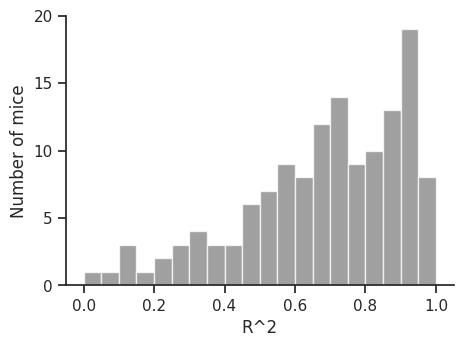

In [ ]:
# individual-mouse PAC-Bayes fits + trials-to-criterion (all labs)
alphas, phis, r2, m_thr, mice = [], [], [], [], []
for lab in labs:
    for sid, arr in all_data[lab].items():
        mice.append((lab, sid))
        m = np.cumsum(arr[:, 1])                           # cumulative trials
        pb = PACBayesCurve(cap=0.5).fit(m, 1 - arr[:, 3])  # fit easy-trial error (col 3)
        alphas.append(pb.params['alpha'])
        phis.append(pb.params['phi'])
        r2.append(pb.params['r2'])
        hit = np.flatnonzero(arr[:, 3] >= 0.84)            # trials to 84% easy performance
        m_thr.append(m[hit[0]] if len(hit) else np.inf)

alphas, phis, r2, m_thr = map(np.array, (alphas, phis, r2, m_thr))

# failed fits: worse than a flat line (R^2 < 0) -- the fit is stuck at chance (alpha, phi ~ 0).
# Drop them here; everything below uses the remaining mice (`mice` = their (lab, subject) keys)
failed = r2 < 0
print(f'{failed.sum()} failed fits (R^2 < 0): ' + ', '.join(
    f'{mice[i][1]} (R^2 = {r2[i]:.2f})' for i in np.flatnonzero(failed)))
alphas, phis, r2, m_thr = alphas[~failed], phis[~failed], r2[~failed], m_thr[~failed]
mice = [key for key, f in zip(mice, failed) if not f]
print(f'{len(failed)} mice - {failed.sum()} failed -> {len(mice)} mice')

# plt R^2
fig = plt.figure(figsize=(5, 3.5))
plt.hist(r2, bins=np.arange(0, 1.05, 0.05), facecolor='grey', alpha=0.75)
plt.xlabel('R^2')
plt.ylabel('Number of mice')
plt.yticks(np.arange(0, plt.gca().get_ylim()[1] + 1, 5))
plt.savefig('./r2_hist.pdf', bbox_inches='tight', dpi=300)
plt.show()

Model Comparsion
- in general, if we assume a 0 floor, the powerlaw fits much better
- if we allow a floor parameter to be fit, then the exponential does slightly better
- we think it's reasonable to assume a $L_D(q^*) = 0$ for the high-contrast trial

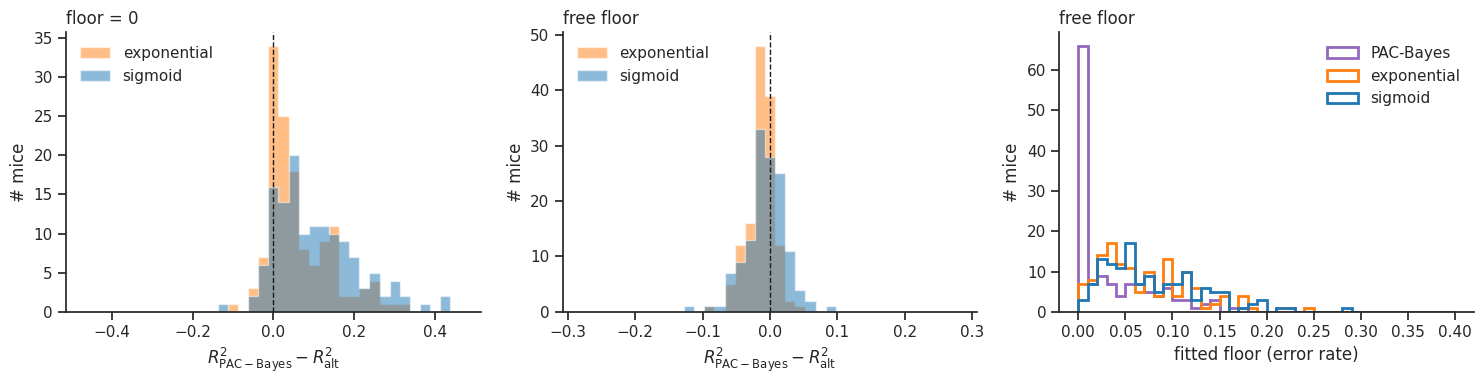

In [7]:
# model comparison: PAC-Bayes vs exponential vs sigmoid, 2 shape parameters each, error capped
# at chance; fit twice: floor fixed at 0 (the theory's asymptote) and floor f as a free 3rd param
# PAC-Bayes:   g(m) = min(f + (2/3) phi/m + (2 phi/m)**alpha, 0.5)
# exponential: g(m) = min(f + a exp(-m/tau), 0.5)
# sigmoid:     g(m) = f + (0.5 - f) / (1 + exp((m - m0)/s))   (starts at chance)

from utils import PACBayesCurve, ExponentialCurve, SigmoidCurve

ALPHA_MAX, FLOOR_MAX = 10.0, 0.4
MODELS = {'PAC-Bayes': PACBayesCurve, 'exponential': ExponentialCurve, 'sigmoid': SigmoidCurve}

def fit_r2(name, m, y, free_floor):
    """R^2 and fitted floor (0 when fixed) of the best multistart fit; nan if every start fails."""
    bounds = {'floor': (0, FLOOR_MAX)}
    if name == 'PAC-Bayes':
        bounds.update(phi=(1, 2 * m.max()), alpha=(0.05, ALPHA_MAX))
    try:
        p = MODELS[name](cap=0.5, fit_floor=free_floor, bounds=bounds, multistart=True).fit(m, y).params
    except RuntimeError:
        return np.nan, np.nan
    return p['r2'], p['floor']

r2_cmp = {fl: {k: [] for k in MODELS} for fl in ('floor = 0', 'free floor')}
floors = {k: [] for k in MODELS}                # fitted floor, free-floor fits
for lab, sid in mice:                            # the 136 mice kept in the individual-fit cell
    arr = all_data[lab][sid]
    m, y = np.cumsum(arr[:, 1]), 1 - arr[:, 3]
    for fl in r2_cmp:
        for k in MODELS:
            r2_k, f_k = fit_r2(k, m, y, fl == 'free floor')
            r2_cmp[fl][k].append(r2_k)
            if fl == 'free floor':
                floors[k].append(f_k)
r2_cmp = {fl: {k: np.array(v) for k, v in d.items()} for fl, d in r2_cmp.items()}
floors = {k: np.array(v) for k, v in floors.items()}

C_MODEL = {'PAC-Bayes': 'tab:purple', 'exponential': 'tab:orange', 'sigmoid': 'tab:blue'}
D_LIM = {'floor = 0': 0.5, 'free floor': 0.3}  # x-range of the R^2 difference; outliers pile at the edges
N_BINS = 41                                     # odd, so the middle bin is centred on 0

fig, axs = plt.subplots(1, 3, figsize=(15, 4))

# left / middle: paired R^2 difference, PAC-Bayes minus each alternative (> 0: PAC-Bayes fits better)
for ax, (fl, d) in zip(axs[:2], r2_cmp.items()):
    lim = D_LIM[fl]
    w = 2 * lim / (N_BINS - 1)
    edges = np.linspace(-lim - w / 2, lim + w / 2, N_BINS + 1)
    for k in ('exponential', 'sigmoid'):
        diff = d['PAC-Bayes'] - d[k]
        ax.hist(np.clip(diff[np.isfinite(diff)], -lim, lim), bins=edges,
                histtype='stepfilled', alpha=0.5, color=C_MODEL[k], label=k)
    ax.axvline(0, color='k', ls='--', lw=1)
    ax.set_xlim(edges[0], edges[-1])
    ax.set_xlabel(r'$R^2_{\mathrm{PAC-Bayes}} - R^2_{\mathrm{alt}}$'); ax.set_ylabel('# mice')
    ax.set_title(fl, loc='left')
    ax.legend(frameon=False, loc='upper left')

# right: fitted floor per model (free-floor fits)
ax = axs[2]
for k, v in floors.items():
    ax.hist(v[np.isfinite(v)], bins=np.linspace(0, FLOOR_MAX, 41), histtype='step', lw=2,
            color=C_MODEL[k], label=k)
ax.set_xlabel('fitted floor (error rate)'); ax.set_ylabel('# mice')
ax.set_title('free floor', loc='left')
ax.legend(frameon=False, loc='upper right')

plt.savefig('./model_compare.pdf', bbox_inches='tight', dpi=300)
plt.tight_layout(); plt.show()

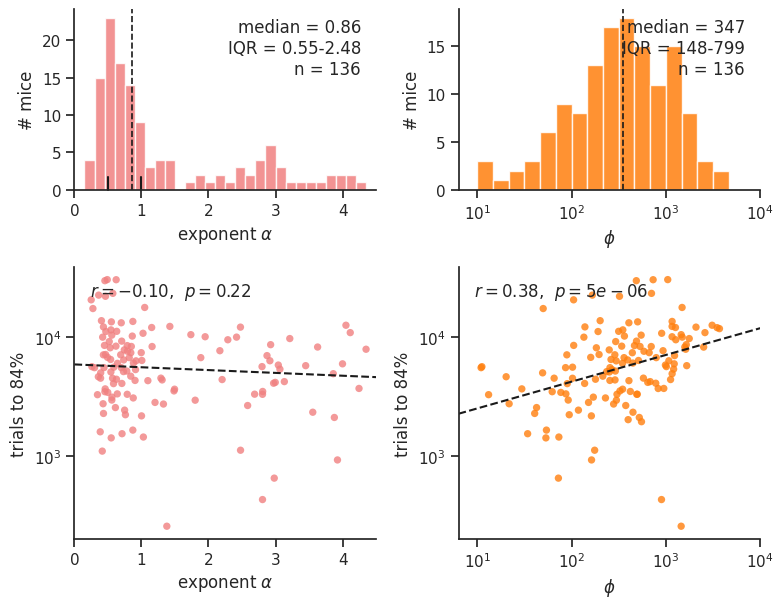

In [8]:
# figure: individual alpha / phi estimates and how each relates to learning speed
C_ALPHA = 'lightcoral'
C_PHI = 'tab:orange'

# all mice from Section 1 (failed fits already dropped; no R^2 selection) that reached the 84%
# criterion; the axes keep a fixed range, so a few extreme fits fall outside the plots but still
# count in the stats / regression
sel = np.isfinite(m_thr)
log_phi = np.log10(phis[sel])
ALPHA_LIM = (0, 4.5)
LOG_PHI_LIM = (1, 4)                 # 10^1 - 10^4
PHI_PAD = 0.2                        # decades of white space left of 10^1 on the phi axes

fig, axs = plt.subplots(2, 2, figsize=(8, 6.25),
                        gridspec_kw=dict(height_ratios=[2, 3]))   # shorter histogram row

# top left: distribution of alpha
ax = axs[0, 0]
ax.hist(alphas[sel], bins=np.arange(ALPHA_LIM[0], ALPHA_LIM[1], 0.15), color=C_ALPHA, alpha=0.85,
        edgecolor='white')
q25, q50, q75 = np.percentile(alphas[sel], [25, 50, 75])
ax.axvline(q50, color='k', lw=1.2, ls='--')
for x_mark in (0.5, 1.0):        # exponent range predicted by the theory
    ax.plot([x_mark, x_mark], [0, 0.07], transform=ax.get_xaxis_transform(),
            color='k', lw=1.5, clip_on=False)
ax.set_xlim(ALPHA_LIM)
ax.set_xlabel(r'exponent $\alpha$'); ax.set_ylabel('# mice')
ax.text(0.95, 0.95, 'median = %.2f\nIQR = %.2f-%.2f\nn = %d' % (q50, q25, q75, sel.sum()),
        transform=ax.transAxes, va='top', ha='right')

# top right: distribution of phi (log scale)
ax = axs[0, 1]
lo, hi = LOG_PHI_LIM
ax.hist(log_phi, bins=np.linspace(lo, hi, int((hi - lo) * 6) + 1), color=C_PHI,
        alpha=0.85, edgecolor='white')
q25, q50, q75 = np.percentile(log_phi, [25, 50, 75])
ax.axvline(q50, color='k', lw=1.2, ls='--')
ax.set_xlim(LOG_PHI_LIM[0] - PHI_PAD, LOG_PHI_LIM[1])
ticks = np.arange(int(lo), int(hi) + 1)
ax.set_xticks(ticks); ax.set_xticklabels([r'$10^{%d}$' % t for t in ticks])
ax.set_xlabel(r'$\phi$'); ax.set_ylabel('# mice')
ax.text(0.95, 0.95, 'median = %.0f\nIQR = %.0f-%.0f\nn = %d'
        % (10 ** q50, 10 ** q25, 10 ** q75, sel.sum()),
        transform=ax.transAxes, va='top', ha='right')

# bottom left: alpha vs learning speed
ax = axs[1, 0]
r_val, pval = pearsonr(alphas[sel], np.log10(m_thr[sel]))      # alpha vs log trials
ax.scatter(alphas[sel], m_thr[sel], s=28, color=C_ALPHA, alpha=0.8, edgecolors='none')
slope, intercept = np.polyfit(alphas[sel], np.log10(m_thr[sel]), 1)
x_line = np.linspace(*ALPHA_LIM, 100)
ax.plot(x_line, 10 ** (intercept + slope * x_line), '--', color='k', lw=1.5)
ax.set_xlim(ALPHA_LIM); ax.set_yscale('log')
ax.minorticks_off()
ax.set_xlabel(r'exponent $\alpha$'); ax.set_ylabel('trials to 84%')
ax.text(0.05, 0.95, r'$r = %.2f$,  $p = %.2g$' % (r_val, pval),
        transform=ax.transAxes, va='top')

# bottom right: phi vs learning speed
ax = axs[1, 1]
r_val, pval = pearsonr(np.log10(phis[sel]), np.log10(m_thr[sel]))   # log phi vs log trials
ax.scatter(phis[sel], m_thr[sel], s=28, color=C_PHI, alpha=0.8, edgecolors='none')
slope, intercept = np.polyfit(np.log10(phis[sel]), np.log10(m_thr[sel]), 1)
x_line = np.linspace(LOG_PHI_LIM[0] - PHI_PAD, LOG_PHI_LIM[1], 100)
ax.plot(10 ** x_line, 10 ** (intercept + slope * x_line), '--', color='k', lw=1.5)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(10 ** (LOG_PHI_LIM[0] - PHI_PAD), 10 ** LOG_PHI_LIM[1])
ax.minorticks_off()
ax.set_xlabel(r'$\phi$'); ax.set_ylabel('trials to 84%')
ax.text(0.05, 0.95, r'$r = %.2f$,  $p = %.2g$' % (r_val, pval),
        transform=ax.transAxes, va='top')

plt.tight_layout()
fig.savefig('ibl_alpha_phi.pdf', dpi=300, bbox_inches='tight')   # vector, for Illustrator
plt.show()

### Rescaling the trial axis: $(m/d)^{\alpha}$

In [36]:
# --- 1. fit the single-component power law to each mouse ---
# g(m) = (d/m)**alpha, capped at chance (0.5), asymptote fixed at zero error.
# d is a trials-to-scale and alpha the exponent, so in log-log each mouse is a straight line.
from utils import PowerLawCurve

# the mice kept in the individual-fit cell (failed fits dropped)
sessions = [(np.cumsum(arr[:, 1]), 1 - arr[:, 3], arr[:, 1])      # cumulative trials, error, weights
            for arr in (all_data[lab][sid] for lab, sid in mice)]

pl_d, pl_alpha, pl_r2 = [], [], []
for m, err, _ in sessions:
    pl = PowerLawCurve(cap=0.5).fit(m, err)
    pl_d.append(pl.params['d']); pl_alpha.append(pl.params['alpha']); pl_r2.append(pl.params['r2'])
pl_d, pl_alpha, pl_r2 = map(np.array, (pl_d, pl_alpha, pl_r2))

print('fitted %d mice | median R^2 %.2f, alpha %.2f, d %.0f'
      % (len(sessions), np.median(pl_r2), np.median(pl_alpha), np.median(pl_d)))

fitted 136 mice | median R^2 0.72, alpha 0.88, d 884


In [37]:
# --- 2. order the mice by d ---
# all mice, ordered by d so the colours (step 4) run with speed; filtering happens in step 4
show = np.argsort(pl_d)
print('%d mice | power-law R^2 %.2f-%.2f, alpha %.2f-%.2f, d %.3g-%.0f'
      % (len(show), pl_r2.min(), pl_r2.max(), pl_alpha.min(), pl_alpha.max(), pl_d.min(), pl_d.max()))

136 mice | power-law R^2 0.04-0.99, alpha 0.27-10.47, d 3.76-5841


In [38]:
# --- 3. bin each mouse's sessions in log trial count ---
# later bins pool more trials, so the noise in log space stays roughly constant instead of
# exploding as the error rate approaches zero; within a bin, error is averaged over trials
N_BINS = 12

binned = []
for i in show:
    m, err, w = sessions[i]
    bin_edges = np.logspace(np.log10(m.min()), np.log10(m.max()), N_BINS + 1)
    idx = np.clip(np.digitize(m, bin_edges) - 1, 0, N_BINS - 1)
    bx, by = [], []
    for b in range(N_BINS):
        s = idx == b
        if s.any():
            bx.append(np.average(m[s], weights=w[s]))
            by.append(np.average(err[s], weights=w[s]))
    binned.append((np.array(bx), np.array(by)))

In [ ]:
# --- 4. keep the N_SHOW smoothest curves, then colour by d ---
# score each binned curve's smoothness (utils.curve_smoothness: minus the RMS second difference of
# log error across the log-spaced bins, i.e. how little the curve zig-zags), rank them, and keep the
# N_SHOW smoothest
from matplotlib.colors import LogNorm
from utils import curve_smoothness

N_SHOW = 100

show_all, binned_all = show, binned                           # all curves, kept for the next figure
ranked = np.argsort(-curve_smoothness(binned_all), kind='stable')   # smoothest first
smoothest = np.sort(ranked[:N_SHOW])                          # sorted back into d order
print('showing the %d smoothest of %d curves' % (len(smoothest), len(show_all)))
show = show_all[smoothest]
binned = [binned_all[k] for k in smoothest]

# colour by d on a log scale (viridis: purple = fast learner, small d -> yellow = slow, large d);
# the scale spans the D_PCT-th to (100 - D_PCT)-th percentile of d
D_PCT = 10
cmap = plt.get_cmap('viridis')
norm = LogNorm(vmin=np.percentile(pl_d[show], D_PCT), vmax=np.percentile(pl_d[show], 100 - D_PCT),
               clip=True)
colors = [cmap(norm(pl_d[i])) for i in show]

showing the 100 smoothest of 136 curves


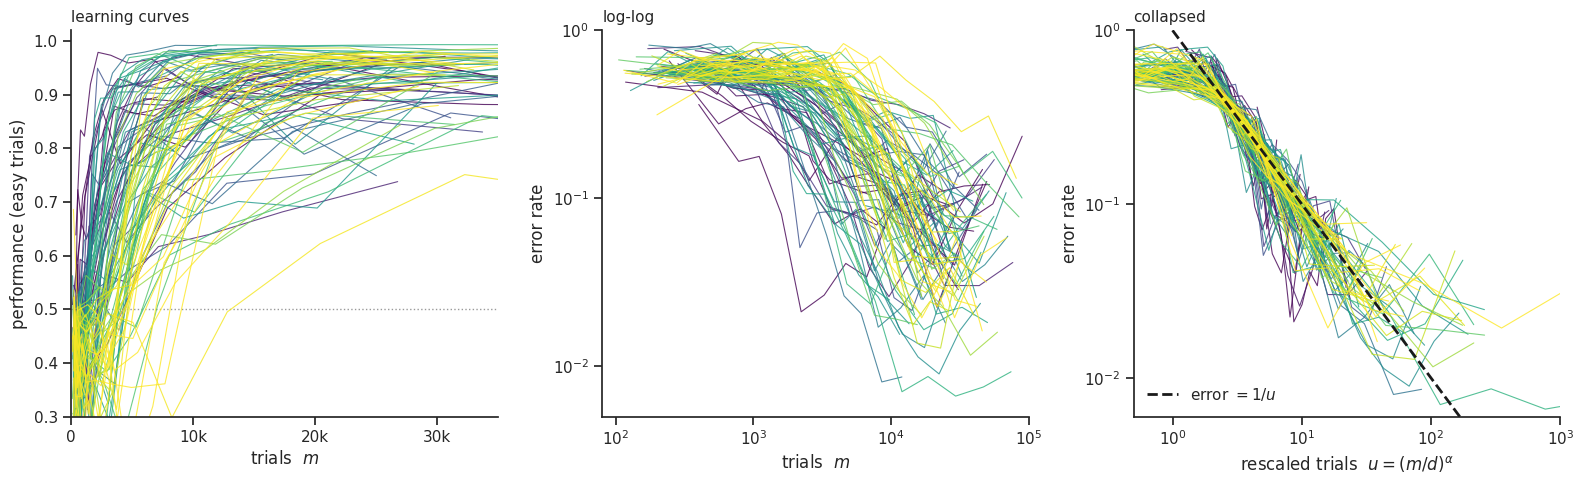

In [ ]:
# set 1: the data as usually plotted, then log-log, then collapsed
LW, ALPHA = 0.8, 0.8                     # thin, slightly translucent lines
fig, axs = plt.subplots(1, 3, figsize=(16, 5))

# left: performance vs trials, the usual IBL view (linear axes)
ax = axs[0]
for (bx, by), c in zip(binned, colors):
    ax.plot(bx, 1 - by, '-', color=c, lw=LW, alpha=ALPHA, solid_capstyle='round')
ax.axhline(0.5, color='0.6', lw=1, ls=':', zorder=0)              # chance
ax.set(xlabel='trials  $m$', ylabel='performance (easy trials)',
       xlim=[0, 3.5e4], ylim=[0.3, 1.02])
ax.set_xticks([0, 1e4, 2e4, 3e4]); ax.set_xticklabels(['0', '10k', '20k', '30k'])
ax.set_title('learning curves', loc='left', fontsize=11)

# middle: the same curves, log-log and log-binned (bins with zero error can't go on a log axis)
ax = axs[1]
for (bx, by), c in zip(binned, colors):
    nonzero = by > 0
    ax.plot(bx[nonzero], by[nonzero], '-', color=c, lw=LW, alpha=ALPHA, solid_capstyle='round')

ax.set(xscale='log', yscale='log', xlabel='trials  $m$', 
       ylabel='error rate', xlim=[8e1, 1e5], ylim=[5e-3, 1])

ax.minorticks_off()
ax.set_title('log-log', loc='left', fontsize=11)

# right: trials rescaled by each mouse's own fit
ax = axs[2]
u_ref = np.logspace(0, 3, 200)
ax.plot(u_ref, 1 / u_ref, '--', color='k', lw=2, zorder=5,        # error = 1/u : slope -1
        label=r'error $= 1/u$')
for (bx, by), i, c in zip(binned, show, colors):
    nonzero = by > 0                                              # zero-error bins: off the log axis
    u = (bx[nonzero] / pl_d[i]) ** pl_alpha[i]
    ax.plot(u, by[nonzero], '-', color=c, lw=LW, alpha=ALPHA, solid_capstyle='round')

ax.set(xscale='log', yscale='log', xlabel=r'rescaled trials  $u = (m/d)^{\alpha}$',
       ylabel='error rate', xlim=[0.5, 1e3], ylim=[6e-3, 1])
ax.minorticks_off()
ax.set_title('collapsed', loc='left', fontsize=11)
ax.legend(frameon=False, loc='lower left')

plt.tight_layout()
fig.savefig('collapse.pdf', dpi=300, bbox_inches='tight')
plt.show()

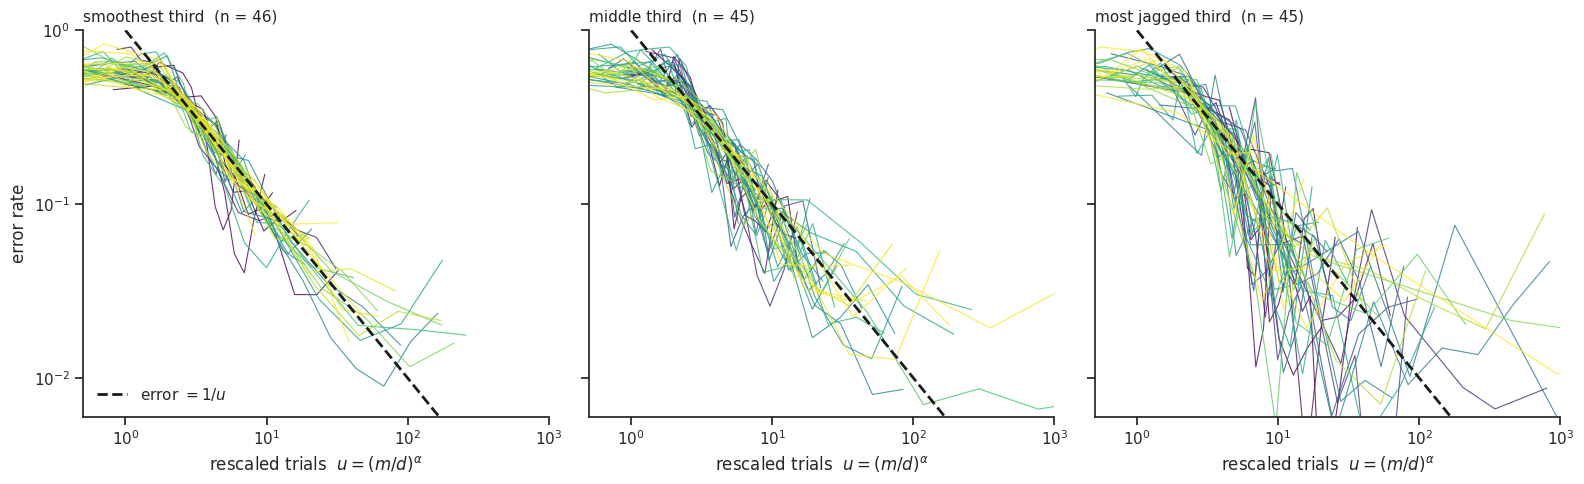

In [ ]:
# all curves split into thirds by smoothness (smoothest -> most jagged), collapsed coordinates only,
# to show what the selection in step 4 leaves out
parts = np.array_split(ranked, 3)
titles = ['smoothest third', 'middle third', 'most jagged third']

fig, axs = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
u_ref = np.logspace(0, 3, 200)
for ax, part, title in zip(axs, parts, titles):
    ax.plot(u_ref, 1 / u_ref, '--', color='k', lw=2, zorder=5, label=r'error $= 1/u$')
    d_part = pl_d[show_all[part]]
    norm_part = LogNorm(vmin=np.percentile(d_part, D_PCT),       # each panel its own colour scale,
                        vmax=np.percentile(d_part, 100 - D_PCT), clip=True)   # D_PCT as in step 4
    for k in np.sort(part):                                       # d order, as in the main figure
        i, (bx, by) = show_all[k], binned_all[k]
        nonzero = by > 0                                          # zero-error bins: off the log axis
        u = (bx[nonzero] / pl_d[i]) ** pl_alpha[i]
        ax.plot(u, by[nonzero], '-', color=cmap(norm_part(pl_d[i])), 
                lw=LW, alpha=ALPHA, solid_capstyle='round')
        
    ax.set(xscale='log', yscale='log', xlabel=r'rescaled trials  $u = (m/d)^{\alpha}$', 
           xlim=[0.5, 1e3], ylim=[6e-3, 1])
    
    ax.minorticks_off()
    ax.set_title('%s  (n = %d)' % (title, len(part)), loc='left', fontsize=11)
axs[0].set_ylabel('error rate')
axs[0].legend(frameon=False, loc='lower left')

plt.tight_layout()
fig.savefig('collapse_by_smoothness.pdf', dpi=300, bbox_inches='tight')
plt.show()